# TCC ML - Extinção
#### João Avila Harduin - 00332195
#### Kauã Cordeiro Cavalheiro - 00331660
#### Luan Bonasorte Capella - 00332061
-----

## Professora orientadora
#### Edith Ranzini

## Notebook 1 de 3 — Construção do Dataset

Este notebook detalha as etapas de construção e gerenciamento do dataset que será utilizado, posteriormente, no treinamento dos modelos de Machine Learning. O projeto aborda um problema de classificação binária, onde o objetivo é prever se uma espécie está 'Ameaçada' ou 'Não Ameaçada'. Este documento complementa a monografia do projeto apresentando a aquisição dos dados de diferentes fontes, análise exploratória, criação de rótulos de ameaça e balanceamento das classes.

### Rodentia — Construção do Dataset para Classificação ML

- **Not Threatened** → Least Concern (LC) + Near Threatened (NT)
- **Threatened** → Vulnerable (VU) + Endangered (EN) + Critically Endangered (CE)

---
**Arquivos:**
- `Rodentia_gbif.csv`: Contém dados de ocorrência de espécies de roedores do GBIF (Global Biodiversity Information Facility).
- `assessments.csv`: Dados de avaliação da Lista Vermelha da IUCN, incluindo categorias de ameaça para diferentes espécies.
- `taxonomy.csv`: Informações taxonômicas detalhadas para as espécies, como família e gênero.

| Notebook | Conteúdo |
|---|---|
| `01_construcao_dataset.ipynb` | Seções 1–5: aquisição, análise exploratória, construção do dataset e pré-processamento |
| `02_modelagem.ipynb` | Seções 6–10: Random Forest, SVM e XGBoost, SMOTE × SMOTENC, ajuste de hiperparâmetros e tabela consolidada |
| `03_fronteira_e_limpeza.ipynb` | Seções 11–13: diagnóstico de fronteira, limpeza (ENN e Passo 1) e Teste 4 |

### Sumário deste notebook

1. Setup
2. Aquisição dos Dados
3. Análise Exploratória
4. Construção do Dataset
5. Pré-processamento (5.4: exportação)

> No Colab, use o painel **Índice** (ícone ☰ à esquerda) para navegar entre as seções. O código reutilizado fica em `src/tcc_extincao/`; as correções metodológicas estão descritas no `README.md`.

### Correções metodológicas (nov/2026)

Correções aplicadas depois da primeira versão dos experimentos (os resultados numéricos mudaram em relação à versão anterior):

1. **Imputação depois do split** (Seção 5.3): os valores ausentes eram preenchidos com a mediana do dataset inteiro, antes da divisão treino/teste. Agora a mediana é calculada só no treino.
2. **SMOTE sem `redlistCategory`** (Seção 6.2): as amostras sintéticas dos experimentos sem vazamento eram geradas com `redlistCategory` participando do cálculo dos vizinhos. Agora o SMOTE é refeito sem a coluna.
3. **Predições sobrescritas no trade-off** (Seção 6.7): o loop do trade-off sobrescrevia `y_pred_rf` e `y_pred_svm`, e a tabela consolidada registrava os modelos com apenas 5 features. Agora o loop usa variáveis próprias.
4. **Balanceamento dentro da validação cruzada** (Seções 7, 8.4, 9.2 e 13): o `GridSearchCV` rodava sobre dados já balanceados, então amostras sintéticas criadas a partir de um fold apareciam na validação de outro, inflando o F1 da validação cruzada. Agora SMOTE/SMOTENC, ENN e `StandardScaler` ficam dentro de um `Pipeline` do imblearn e são refeitos em cada fold.
5. **SVM padrão escalonado** (Seções 8.3, 12.1 e 12.2): os SVMs sem tuning com SMOTENC não eram escalonados, enquanto os otimizados eram. A comparação padrão × otimizado misturava o efeito do tuning com o do escalonamento.
6. **Diagnóstico de fronteira sem `redlistCategory`** (Seção 11): o Random Forest do Passo 1 usava `redlistCategory`, da qual o rótulo é derivado. A lista de espécies suspeitas (e o Teste 3) depende dessa correção.
7. **Rótulo do SVM otimizado com SMOTENC** (Seção 10): estava registrado como `SMOTENC (Escalado)`, o que quebrava os gráficos da Seção 13.4.

## 1. Setup

Prepara o ambiente (no Colab, clona o repositório e instala o `matplotlib-venn`), imports e opções de exibição.

In [1]:
# No Colab, clona o repositório (os dados são baixados do Google Drive pelo
# próprio notebook); localmente, usa a pasta do repositório
import sys
from pathlib import Path

REPO_URL = 'https://github.com/kcac1108/tcc-ml-extincao.git'

if 'google.colab' in sys.modules:
    RAIZ = Path('/content/tcc-ml-extincao')
    if not RAIZ.exists():
        !git clone -q {REPO_URL} {RAIZ}
    %pip install -q matplotlib-venn
else:
    RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'tcc_extincao').exists())

sys.path.insert(0, str(RAIZ / 'src'))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib_venn import venn2
from imblearn.over_sampling import SMOTE

from tcc_extincao import config, dados, avaliacao, preprocessamento as prep
from tcc_extincao.config import RANDOM_STATE

pd.set_option('display.max_columns', 60)
pd.set_option('display.max_colwidth', 80)

## 2. Aquisição dos Dados
Estamos usando `gdown` para baixar do Google Drive os arquivos que utilizaremos neste projeto (arquivos que já estão em `data/` não são baixados de novo).

In [3]:
dados.baixar_dados()

assessments.csv já existe, download pulado.
Rodentia_gbif.csv já existe, download pulado.
taxonomy.csv já existe, download pulado.


In [4]:
gbif, assessments, taxonomy = dados.ler_fontes()

print(f'GBIF        : {gbif.shape[0]:,} linhas x {gbif.shape[1]} colunas')
print(f'Assessments : {assessments.shape[0]:,} linhas x {assessments.shape[1]} colunas')
print(f'Taxonomy    : {taxonomy.shape[0]:,} linhas x {taxonomy.shape[1]} colunas')

GBIF        : 513,541 linhas x 50 colunas
Assessments : 2,386 linhas x 23 colunas
Taxonomy    : 2,386 linhas x 15 colunas


## 3. Análise Exploratória

### 3.1 Exploração inicial

In [5]:
print('=== Categorias Red List ===')
print(assessments['redlistCategory'].value_counts())

print(f'\nEspécies únicas no GBIF       : {gbif["species"].nunique():,}')
print(f'Espécies únicas em Assessments: {assessments["scientificName"].nunique():,}')

gbif_sp   = set(gbif['species'].dropna().unique())
assess_sp = set(assessments['scientificName'].dropna().unique())
print(f'\nSobreposição direta (nome exato): {len(gbif_sp & assess_sp):,} espécies')

=== Categorias Red List ===
redlistCategory
Least Concern            1525
Data Deficient            367
Endangered                142
Vulnerable                137
Near Threatened           111
Critically Endangered      67
Extinct                    37
Name: count, dtype: int64

Espécies únicas no GBIF       : 848
Espécies únicas em Assessments: 2,386

Sobreposição direta (nome exato): 757 espécies


### 3.2 Interseção dos dados (Diagrama de Venn)

O diagrama de Venn abaixo ilustra a intersecção entre as espécies presentes nos dados do GBIF (registros de ocorrência) e as espécies com dados de avaliação da IUCN (Red List). Esta intersecção nos mostra as espécies para as quais temos tanto informações de ocorrência quanto seu status de ameaça.

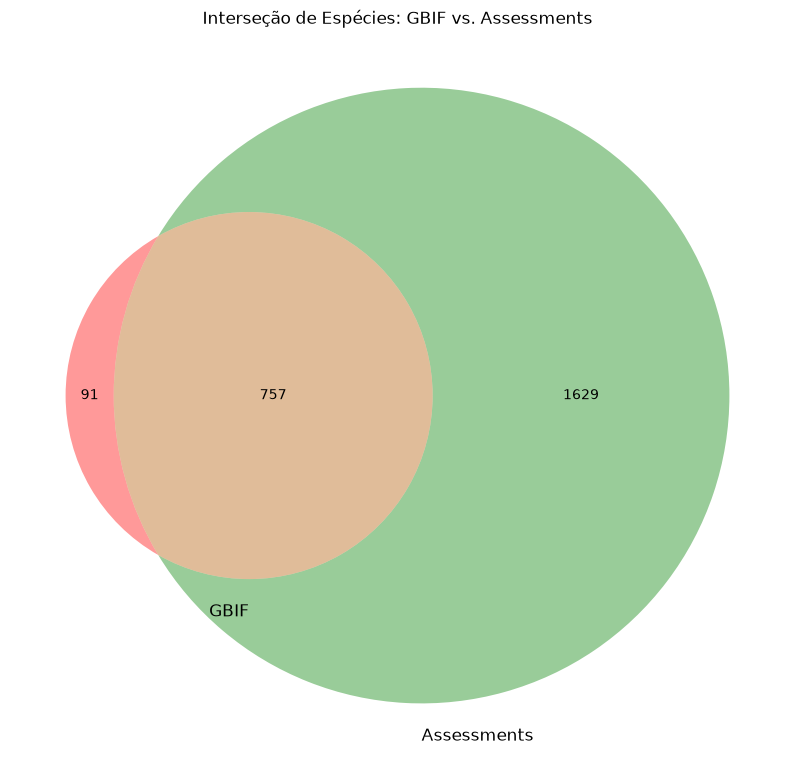

In [6]:
# Espécies únicas no GBIF e no Assessments
gbif_species = set(gbif['species'].dropna().unique())
assessments_species = set(assessments['scientificName'].dropna().unique())

plt.figure(figsize=(10, 10))
v = venn2([gbif_species, assessments_species], ('GBIF', 'Assessments'))
plt.title('Interseção de Espécies: GBIF vs. Assessments')

plt.show()

## 4. Construção do Dataset

### 4.1 Criação dos rótulos (labels)

Excluímos `Data Deficient` (DD) e `Extinct` (EX/EW) pois não se enquadram na classificação binária proposta. O mapeamento de categorias para rótulos está em `config.INCLUDE_CATS`.

In [7]:
assess_labeled = dados.criar_rotulos(assessments)

print('Distribuição dos rótulos:')
print(assess_labeled['label'].value_counts())
print(f'\nTotal de espécies avaliáveis: {len(assess_labeled):,}')

Distribuição dos rótulos:
label
Not Threatened    1636
Threatened         346
Name: count, dtype: int64

Total de espécies avaliáveis: 1,982


Quantidade de espécies segundo a classificação do Red List Category

/var/folders/mh/wnqhssl12h53gk5fbcyz_l180000gn/T/ipykernel_54719/2241380785.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='redlistCategory', data=assessments, order=assessments['redlistCategory'].value_counts().index, palette='viridis')


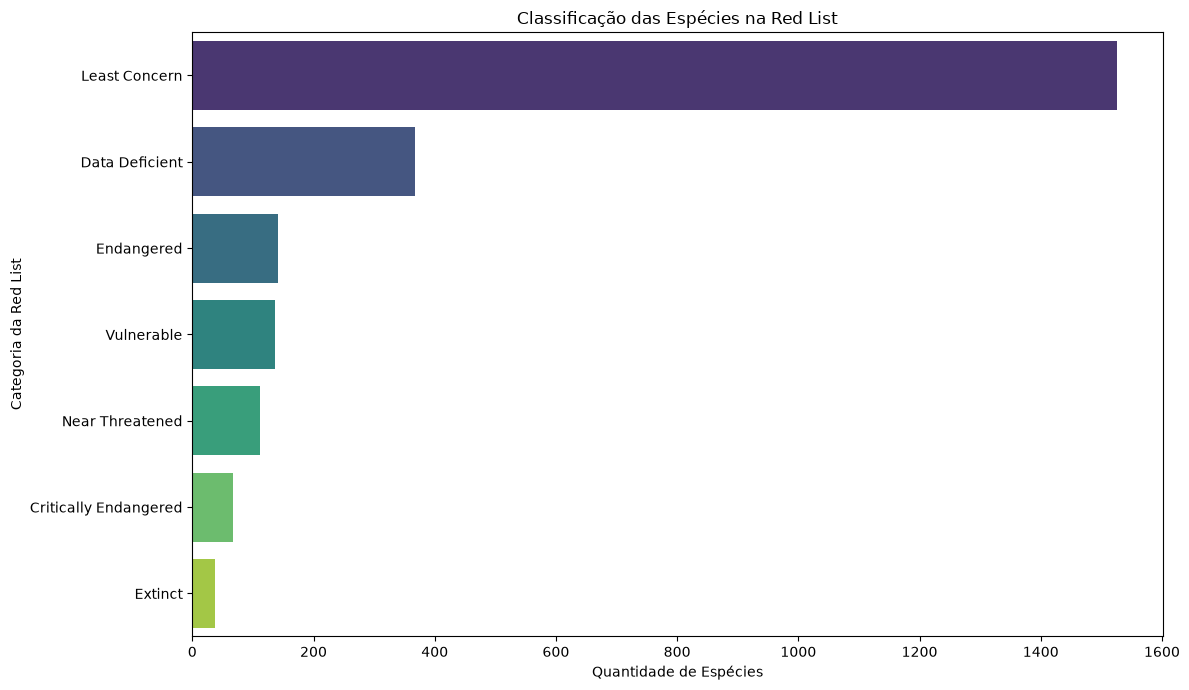

In [8]:
plt.figure(figsize=(12, 7))
sns.countplot(y='redlistCategory', data=assessments, order=assessments['redlistCategory'].value_counts().index, palette='viridis')
plt.title('Classificação das Espécies na Red List')
plt.xlabel('Quantidade de Espécies')
plt.ylabel('Categoria da Red List')
plt.tight_layout()
plt.show()

### 4.2 Agregação do GBIF por espécie

O GBIF contém **ocorrências** (uma linha por registro de campo). Precisamos **agregar por espécie** para obter uma linha por espécie com features numéricas.

In [9]:
gbif_features = dados.agregar_gbif(gbif)
print(f'Features GBIF geradas: {gbif_features.shape[0]} espécies x {gbif_features.shape[1]} colunas')
gbif_features.head()

Features GBIF geradas: 848 espécies x 21 colunas


,species,n_occurrences,n_countries,lat_mean,lat_std,lon_mean,lon_std,lat_min,lat_max,lon_min,lon_max,year_min,year_max,n_months_active,n_basis_types,coord_uncertainty_mean,lat_range,lon_range,year_range,pct_human_obs,pct_specimen
0,Abrocoma bennettii,5,1,-31.188909,0.987212,-71.104310,0.348238,-32.460043,-29.879571,-71.653162,-70.703727,2025,2025,3,1,369.000000,2.580472,0.949435,0,1.0,0.0
1,Abrothrix andinus,7,2,-31.184714,4.978968,-69.853495,0.508700,-34.176451,-21.076950,-70.323657,-68.859025,2025,2026,4,1,8453.571429,13.099501,1.464632,1,1.0,0.0
2,Abrothrix jelskii,4,3,-16.362268,1.844518,-70.023967,1.449604,-18.252215,-13.857592,-71.298153,-68.420858,2025,2025,3,1,472.500000,4.394623,2.877295,0,1.0,0.0
3,Abrothrix longipilis,8,2,-37.253593,4.614916,-72.181202,0.749073,-41.734153,-30.832701,-73.311905,-71.451988,2025,2026,6,1,488.500000,10.901452,1.859917,1,1.0,0.0
4,Abrothrix olivaceus,39,2,-36.444857,8.844692,-71.752568,0.992795,-54.101145,-29.571791,-73.601674,-68.939628,2025,2026,9,1,1823.310345,24.529354,4.662046,1,1.0,0.0


Gráfico que mostra várias ocorrências de uma mesma espécie

/var/folders/mh/wnqhssl12h53gk5fbcyz_l180000gn/T/ipykernel_54719/1410322139.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='n_occurrences', y='species', data=top_species_new, palette='viridis')


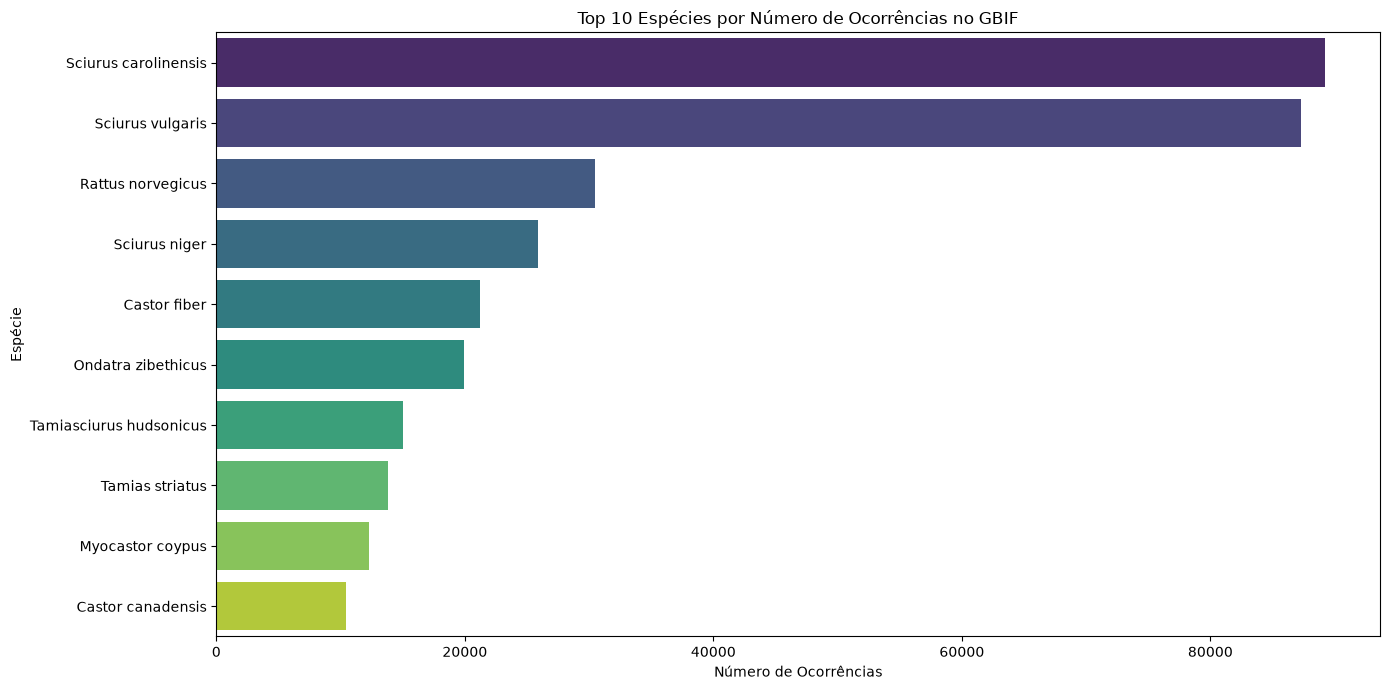

In [10]:
# Obter as top 10 espécies com mais ocorrências
top_species_new = gbif_features.sort_values(by='n_occurrences', ascending=False).head(10)

plt.figure(figsize=(14, 7))
sns.barplot(x='n_occurrences', y='species', data=top_species_new, palette='viridis')
plt.title('Top 10 Espécies por Número de Ocorrências no GBIF')
plt.xlabel('Número de Ocorrências')
plt.ylabel('Espécie')
plt.tight_layout()
plt.show()

### 4.3 Junção das três fontes

A chave de junção é o `scientificName` (nome binomial da espécie).

Nesta etapa, unimos as informações das três fontes de dados (`assessments`, `taxonomy` e `gbif_features`) em um único dataset. O processo ocorre da seguinte forma:

1.  **Combinando Avaliações da IUCN e Taxonomia**: Primeiramente, juntamos os dados de avaliação da IUCN (`assessments_slim`) com as informações detalhadas de classificação das espécies (`tax_slim`), como família e gênero. Isso nos garante que cada espécie avaliada tenha seus dados taxonômicos.
2.  **Unindo com Dados de Ocorrência do GBIF**: Em seguida, o conjunto de dados resultante é unido aos dados agregados de ocorrência do GBIF (`gbif_features`). Fazemos isso de uma maneira que só mantemos as espécies que possuem tanto um status de ameaça quanto registros de ocorrência. Isso é fundamental para nosso problema de classificação, pois precisamos de ambos os tipos de informação para cada espécie.

In [11]:
dataset = dados.juntar_fontes(assess_labeled, taxonomy, gbif_features)

print(f'Dataset final: {dataset.shape[0]} espécies x {dataset.shape[1]} colunas')
print(f'\nDistribuição de rótulos:')
print(dataset['label'].value_counts())
print(f'\nRatio Not Threatened / Threatened: {dataset["label"].value_counts()["Not Threatened"] / dataset["label"].value_counts()["Threatened"]:.1f}x')

Dataset final: 721 espécies x 30 colunas

Distribuição de rótulos:
label
Not Threatened    661
Threatened         60
Name: count, dtype: int64

Ratio Not Threatened / Threatened: 11.0x


Abaixo, o diagrama de Venn ilustra a intersecção entre as espécies que possuem informações taxonômicas e de avaliação da IUCN (união de 'Assessments' e 'Taxonomy') e as espécies para as quais temos dados de ocorrência agregados do GBIF. Este diagrama destaca o número de espécies comuns a esses dois conjuntos de dados principais que foram utilizados para construir o dataset final.

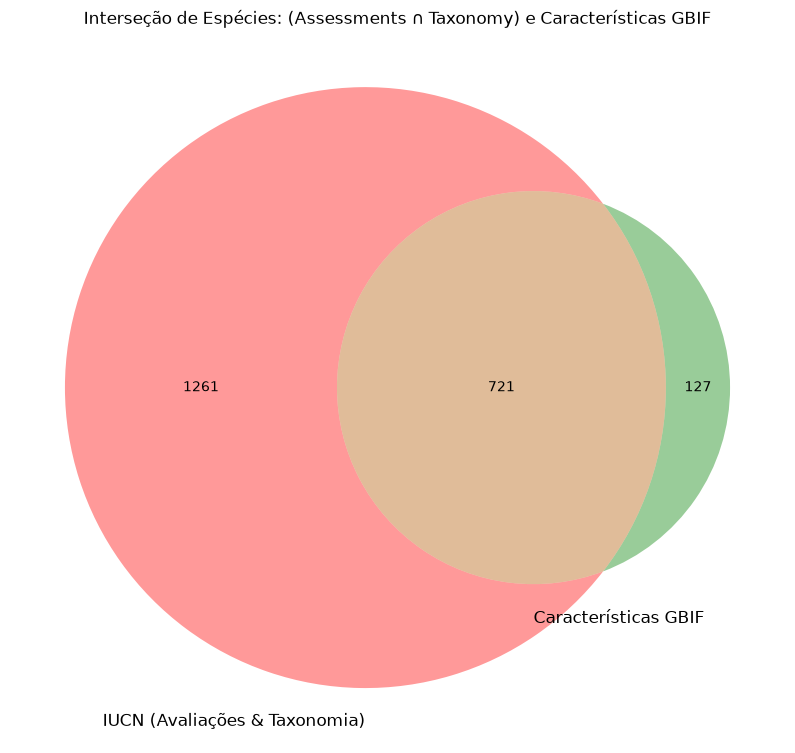

In [12]:
# Define os conjuntos de espécies únicas de cada fonte
assessments_species_set = set(assess_labeled['scientificName'].dropna().unique())
taxonomy_species_set = set(taxonomy['scientificName'].dropna().unique())
gbif_features_species_set = set(gbif_features['species'].dropna().unique())

# Calcula a interseção das espécies das Avaliações (Assessments) e Taxonomia
assessments_intersection_taxonomy_species_set = assessments_species_set.intersection(taxonomy_species_set)

plt.figure(figsize=(10, 10))
venn2(
    [assessments_intersection_taxonomy_species_set, gbif_features_species_set],
    ('IUCN (Avaliações & Taxonomia)', 'Características GBIF') # Rótulo ajustado para maior clareza
)
plt.title('Interseção de Espécies: (Assessments \u2229 Taxonomy) e Características GBIF')
plt.show()

### 4.4 Visualização do dataset final

O arquivo `rodentia_dataset.csv` é exportado na Seção 5.4.

In [13]:
print(f'Shape: {dataset.shape}')
print(f'\nColunas:')
for c in dataset.columns:
    print(f'  {c}')

dataset.head()

Shape: (721, 30)

Colunas:
  scientificName
  redlistCategory
  label
  populationTrend
  yearPublished
  systems
  realm
  possiblyExtinct
  familyName
  genusName
  n_occurrences
  n_countries
  lat_mean
  lat_std
  lon_mean
  lon_std
  lat_min
  lat_max
  lon_min
  lon_max
  year_min
  year_max
  n_months_active
  n_basis_types
  coord_uncertainty_mean
  lat_range
  lon_range
  year_range
  pct_human_obs
  pct_specimen


,scientificName,redlistCategory,label,populationTrend,yearPublished,systems,realm,possiblyExtinct,familyName,genusName,n_occurrences,n_countries,lat_mean,lat_std,lon_mean,lon_std,lat_min,lat_max,lon_min,lon_max,year_min,year_max,n_months_active,n_basis_types,coord_uncertainty_mean,lat_range,lon_range,year_range,pct_human_obs,pct_specimen
0,Arvicola sapidus,Near Threatened,Not Threatened,Decreasing,2024,Terrestrial|Freshwater (=Inland waters),Palearctic,False,CRICETIDAE,Arvicola,573,3,41.205862,2.118200,-4.129135,2.683222,36.068254,48.988522,-8.999253,6.507744,2025,2026,10,2,1346.196809,12.920268,15.506997,1,0.987784,0.0
1,Eliomys quercinus,Vulnerable,Threatened,Decreasing,2024,Terrestrial,Palearctic,False,GLIRIDAE,Eliomys,1052,11,49.002018,3.164541,6.408456,3.482460,36.363822,52.200000,-8.337970,15.096889,2025,2026,12,2,856.212656,15.836178,23.434859,1,0.998099,0.0
2,Abrocoma bennettii,Least Concern,Not Threatened,Unknown,2016,Terrestrial,Neotropical,False,ABROCOMIDAE,Abrocoma,5,1,-31.188909,0.987212,-71.104310,0.348238,-32.460043,-29.879571,-71.653162,-70.703727,2025,2025,3,1,369.000000,2.580472,0.949435,0,1.000000,0.0
3,Anomalurus pelii,Least Concern,Not Threatened,Decreasing,2021,Terrestrial,Afrotropical,False,ANOMALURIDAE,Anomalurus,5,1,5.371652,0.049728,-1.384268,0.020054,5.347050,5.460569,-1.403862,-1.352826,2025,2026,4,1,5603.000000,0.113519,0.051036,1,1.000000,0.0
4,Anomalurus beecrofti,Least Concern,Not Threatened,Unknown,2016,Terrestrial,Afrotropical,False,ANOMALURIDAE,Anomalurus,6,2,4.474379,1.202507,3.653773,9.761769,2.920300,5.286472,-2.651713,16.256762,2025,2026,2,1,124.833333,2.366172,18.908475,1,1.000000,0.0


### 4.5 Disparidade entre os rótulos no dataset

Quantidade de cada classificação:
label
Not Threatened    661
Threatened         60
Name: count, dtype: int64


/var/folders/mh/wnqhssl12h53gk5fbcyz_l180000gn/T/ipykernel_54719/90452803.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label_counts.index, y=label_counts.values, palette='coolwarm')


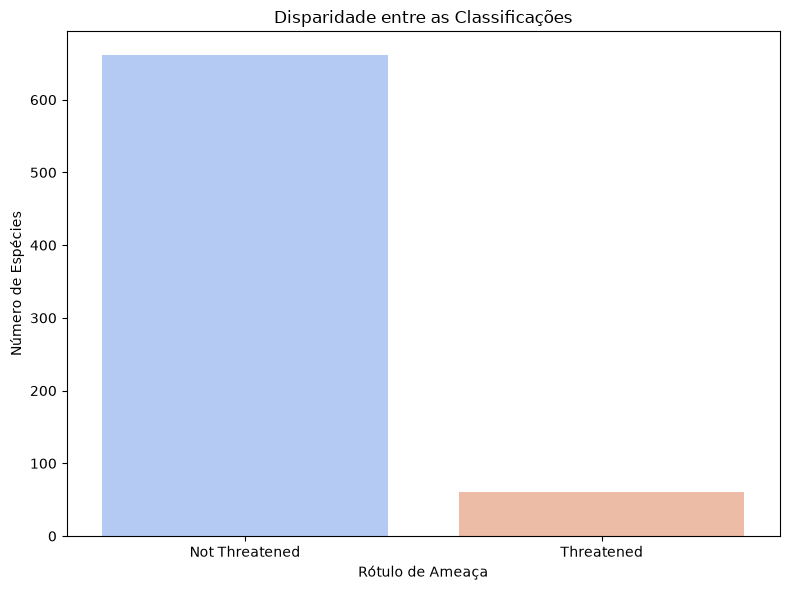

In [14]:
label_counts = dataset['label'].value_counts()

print("Quantidade de cada classificação:")
print(label_counts)

plt.figure(figsize=(8, 6))
sns.barplot(x=label_counts.index, y=label_counts.values, palette='coolwarm')
plt.title('Disparidade entre as Classificações')
plt.xlabel('Rótulo de Ameaça')
plt.ylabel('Número de Espécies')
plt.xticks(ticks=[0, 1], labels=['Not Threatened', 'Threatened'])
plt.tight_layout()
plt.show()

## 5. Pré-processamento

### 5.1 Encoding do dataset

Para que o dataset possa ser utilizado para treinamento de modelos de Machine Learning, transformamos nossas colunas de texto em números.

* Limpeza: Remoção do scientificName.

* Binário (0 ou 1): Conversão direta das colunas possiblyExtinct e label.

* Ordinal: Mapeamento da redlistCategory em uma escala numérica crescente (0 a 6), ensinando ao modelo a hierarquia de risco da IUCN.

* Multi-Label: Separação dos habitats da coluna systems (divididos por |) em colunas independentes, permitindo que um animal habite múltiplos ambientes ao mesmo tempo.

* One-Hot Encoding: Criação de colunas dummy (0 ou 1) para categorias sem ordem de grandeza (realm, populationTrend, familyName, genusName), evitando criar falsas hierarquias matemáticas.

In [15]:
df, colunas_systems = prep.codificar(dataset)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 721 entries, 0 to 720
Columns: 345 entries, redlistCategory to genusName_Zyzomys
dtypes: float64(13), int64(332)
memory usage: 1.9 MB


In [16]:
df.head()

,redlistCategory,label,yearPublished,possiblyExtinct,n_occurrences,n_countries,lat_mean,lat_std,lon_mean,lon_std,lat_min,lat_max,lon_min,lon_max,year_min,year_max,n_months_active,n_basis_types,coord_uncertainty_mean,lat_range,lon_range,year_range,pct_human_obs,pct_specimen,Freshwater (=Inland waters),Terrestrial,populationTrend_Decreasing,populationTrend_Increasing,populationTrend_Stable,populationTrend_Unknown,...,genusName_Spermophilus,genusName_Steatomys,genusName_Stylodipus,genusName_Sundamys,genusName_Sundasciurus,genusName_Tachyoryctes,genusName_Tamias,genusName_Tamiasciurus,genusName_Tamiops,genusName_Tatera,genusName_Thallomys,genusName_Thaptomys,genusName_Thomasomys,genusName_Thomomys,genusName_Thrichomys,genusName_Thryonomys,genusName_Tokudaia,genusName_Transandinomys,genusName_Trichys,genusName_Trinomys,genusName_Tylomys,genusName_Urocitellus,genusName_Uromys,genusName_Vandeleuria,genusName_Wiedomys,genusName_Xerospermophilus,genusName_Xerus,genusName_Zapus,genusName_Zygodontomys,genusName_Zyzomys
0,1,0,2024,0,573,3,41.205862,2.118200,-4.129135,2.683222,36.068254,48.988522,-8.999253,6.507744,2025,2026,10,2,1346.196809,12.920268,15.506997,1,0.987784,0.0,1,1,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,2,1,2024,0,1052,11,49.002018,3.164541,6.408456,3.482460,36.363822,52.200000,-8.337970,15.096889,2025,2026,12,2,856.212656,15.836178,23.434859,1,0.998099,0.0,0,1,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,2016,0,5,1,-31.188909,0.987212,-71.104310,0.348238,-32.460043,-29.879571,-71.653162,-70.703727,2025,2025,3,1,369.000000,2.580472,0.949435,0,1.000000,0.0,0,1,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,2021,0,5,1,5.371652,0.049728,-1.384268,0.020054,5.347050,5.460569,-1.403862,-1.352826,2025,2026,4,1,5603.000000,0.113519,0.051036,1,1.000000,0.0,0,1,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,2016,0,6,2,4.474379,1.202507,3.653773,9.761769,2.920300,5.286472,-2.651713,16.256762,2025,2026,2,1,124.833333,2.366172,18.908475,1,1.000000,0.0,0,1,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


### 5.2 Matriz de correlação das variáveis principais

Para uma visualização mais clara das relações entre as variáveis mais importantes, selecionamos um subconjunto de features do dataset `df` já codificado. Esta matriz destacará as correlações mais fortes e relevantes para a previsão do `label` (ameaçado/não ameaçado).

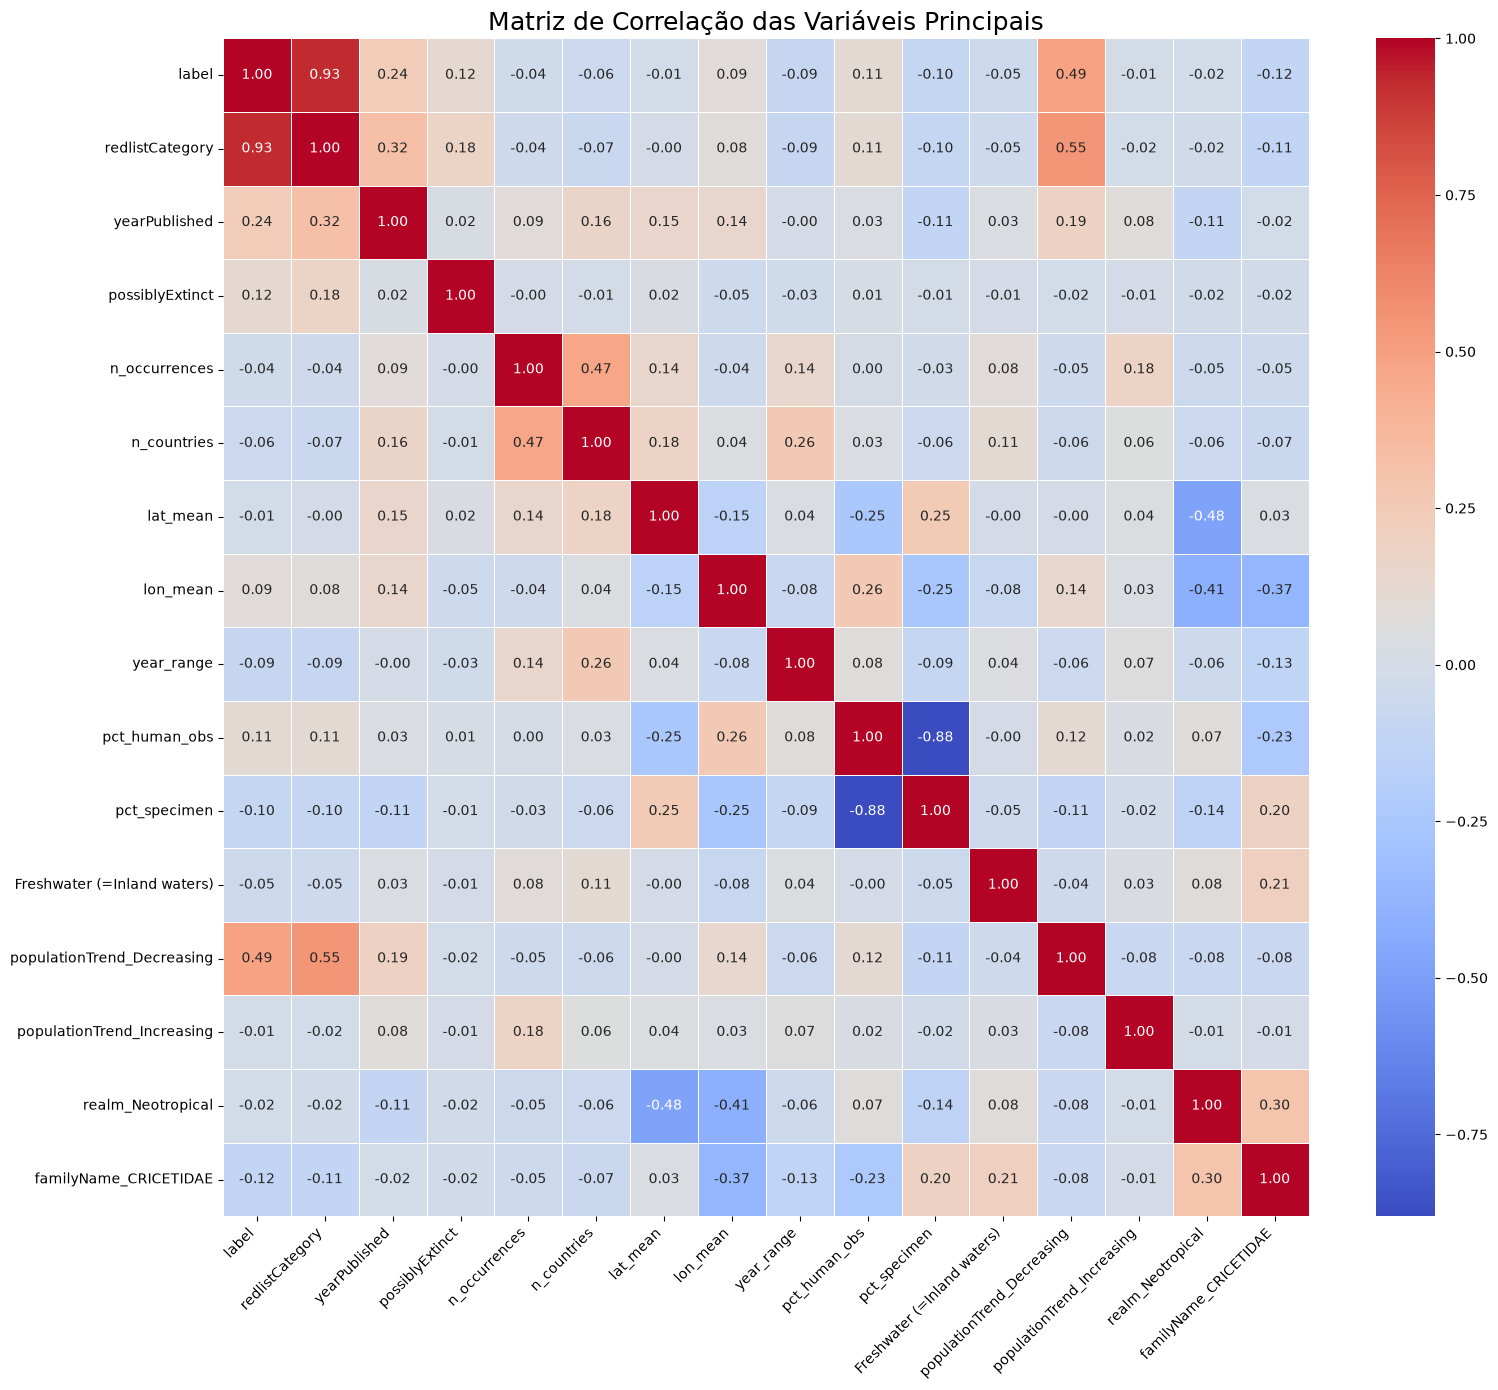

In [17]:
# Selecionar um subconjunto de variáveis principais para uma matriz de correlação mais interpretável
main_vars = [
    'label', # Variável alvo
    'redlistCategory',
    'yearPublished',
    'possiblyExtinct',
    'n_occurrences',
    'n_countries',
    'lat_mean',
    'lon_mean',
    'year_range',
    'pct_human_obs',
    'pct_specimen',
    'Freshwater (=Inland waters)', # Exemplo de sistema
    'populationTrend_Decreasing', # Exemplo de tendência populacional
    'populationTrend_Increasing',
    'realm_Neotropical', # Exemplo de reino
    'familyName_CRICETIDAE' # Exemplo de família
]

# Filtrar o DataFrame apenas com as variáveis selecionadas
df_main_vars = df[main_vars]

# Calcular a matriz de correlação para as variáveis principais
correlation_matrix_main = df_main_vars.corr()

plt.figure(figsize=(16, 14))
sns.heatmap(correlation_matrix_main, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5, cbar=True)
plt.title('Matriz de Correlação das Variáveis Principais', fontsize=18)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

#### Pares de variáveis contínuas com alta correlação

Identificamos pares de features contínuas com |r| > 0.85, que carregam informação redundante, e listamos as candidatas a descarte (a amplitude geográfica `lat_range`/`lon_range` é mantida por ser um preditor ecológico direto).

In [18]:
# Variáveis contínuas agregadas do GBIF
numeric_cols = [
    "n_occurrences", "n_countries", "lat_mean", "lat_std", "lon_mean", "lon_std",
    "lat_min", "lat_max", "lon_min", "lon_max", "year_min", "year_max",
    "n_months_active", "n_basis_types", "coord_uncertainty_mean",
    "lat_range", "lon_range", "year_range", "pct_human_obs", "pct_specimen",
]

print("=== PARES COM ALTA CORRELAÇÃO (|r| > 0.85) ===")
for row, col, val in avaliacao.pares_alta_correlacao(dataset, numeric_cols):
    print(f"{row} <--> {col}: r = {val:.2f}")

# Sugestão de descarte biológico/matemático direto:
# - Manter lat_range e lon_range (amplitude geográfica é preditor ecológico direto)
# - Descartar lat_min, lat_max, lon_min, lon_max
cols_to_drop_corr = ["lat_min", "lat_max", "lon_min", "lon_max", "year_min"]
print(f"\nColunas recomendadas para descarte: {cols_to_drop_corr}")

=== PARES COM ALTA CORRELAÇÃO (|r| > 0.85) ===
lat_mean <--> lat_min: r = 0.93
lat_mean <--> lat_max: r = 0.97
lon_mean <--> lon_min: r = 0.97
lon_mean <--> lon_max: r = 0.96
lon_min <--> lon_max: r = 0.89
lon_std <--> lon_range: r = 0.86
year_max <--> year_range: r = 0.94
pct_human_obs <--> pct_specimen: r = -0.88

Colunas recomendadas para descarte: ['lat_min', 'lat_max', 'lon_min', 'lon_max', 'year_min']


### 5.3 Balanceamento (SMOTE)

Nosso dataset possui um forte desbalanceamento: temos muito mais registros de espécies "Não Ameaçadas" (0) do que "Ameaçadas" (1). Se treinarmos o modelo assim, ele ficará enviesado para a classe majoritária.

Como técnica de balanceamento optamos pelo Oversampling, mais especificamente o SMOTE.

**Passo 1 —** Separar quem é a "resposta" (y) e quem são as "características" (X).

O nosso objetivo é prever a coluna 'label' (0 = Não Ameaçado, 1 = Ameaçado)

In [19]:
# Quantidade de valores vazios (NaN) por coluna; o preenchimento é feito
# depois do split treino/teste (próximo passo)
print(df.isna().sum().sort_values(ascending=False).head(10))

X, y = prep.separar_X_y(df)

lon_std                   147
lat_std                   147
coord_uncertainty_mean     29
lat_min                     1
lat_range                   1
lon_max                     1
lon_min                     1
lat_max                     1
lon_range                   1
lon_mean                    1
dtype: int64


**Passo 2 —** Separar treino e teste **antes** do SMOTE

`test_size=TEST_SIZE` (0.2) significa que 20% dos dados ficam escondidos para teste.

`stratify=y` garante que a proporção original de ameaçados seja mantida na divisão.

Os valores ausentes (NaN) são preenchidos **depois** da divisão, com a mediana calculada apenas no treino.

In [20]:
X_treino, X_teste, y_treino, y_teste = prep.dividir_treino_teste(X, y)

print("--- ANTES DO SMOTE (Dados de Treino) ---")
print(y_treino.value_counts())

--- ANTES DO SMOTE (Dados de Treino) ---
label
0    528
1     48
Name: count, dtype: int64


**Passo 3 —** Inicializar e aplicar o SMOTE exclusivamente nos dados de treino

In [21]:
smote = SMOTE(random_state=RANDOM_STATE)
X_treino_balanceado, y_treino_balanceado = smote.fit_resample(X_treino, y_treino)

print("--- DEPOIS DO SMOTE (Dados de Treino Balanceados) ---")
print(y_treino_balanceado.value_counts())

--- DEPOIS DO SMOTE (Dados de Treino Balanceados) ---
label
0    528
1    528
Name: count, dtype: int64


#### Visualização do balanceamento com SMOTE
Estes gráficos mostram a distribuição das classes 'Not Threatened' (0) e 'Threatened' (1) nos dados de treinamento antes e depois da aplicação do SMOTE (Synthetic Minority Over-sampling Technique). O objetivo do SMOTE é igualar o número de amostras da classe minoritária, criando instâncias sintéticas, para evitar o viés do modelo.

/var/folders/mh/wnqhssl12h53gk5fbcyz_l180000gn/T/ipykernel_54719/369825295.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_treino, ax=axes[0], palette='viridis')
/var/folders/mh/wnqhssl12h53gk5fbcyz_l180000gn/T/ipykernel_54719/369825295.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_treino_balanceado, ax=axes[1], palette='viridis')


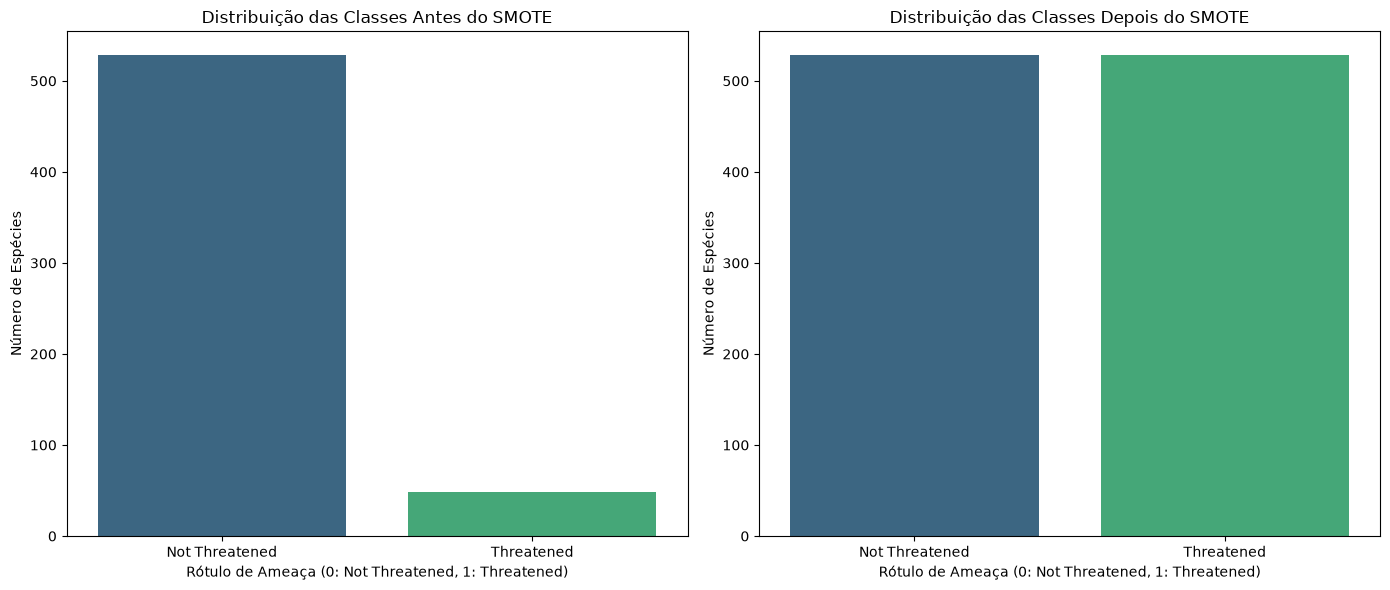

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot antes do SMOTE
sns.countplot(x=y_treino, ax=axes[0], palette='viridis')
axes[0].set_title('Distribuição das Classes Antes do SMOTE')
axes[0].set_xlabel('Rótulo de Ameaça (0: Not Threatened, 1: Threatened)')
axes[0].set_ylabel('Número de Espécies')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Not Threatened', 'Threatened'])

# Plot depois do SMOTE
sns.countplot(x=y_treino_balanceado, ax=axes[1], palette='viridis')
axes[1].set_title('Distribuição das Classes Depois do SMOTE')
axes[1].set_xlabel('Rótulo de Ameaça (0: Not Threatened, 1: Threatened)')
axes[1].set_ylabel('Número de Espécies')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Not Threatened', 'Threatened'])

plt.tight_layout()
plt.show()

### 5.4 Exportação dos datasets

Os arquivos são salvos em `data/final_data/` (no Colab, essa pasta fica no armazenamento temporário da sessão; baixe os arquivos antes de encerrá-la).

In [23]:
# Dataset unificado (três fontes), antes do encoding
dataset.to_csv(config.OUTPUT_PATH, index=False)
print(f"Exportado: {config.OUTPUT_PATH}  (shape: {dataset.shape})")

# Dataset completo codificado, antes do split treino/teste. Os NaN são preenchidos
# com a mediana só neste arquivo, para manter o mesmo formato da versão anterior
# (nos experimentos, a imputação usa apenas a mediana do treino)
df.fillna(df.median()).to_csv(config.ENCODED_PATH, index=False)
print(f"Exportado: {config.ENCODED_PATH}  (shape: {df.shape})")

Exportado: /Users/kauacordeiro/Downloads/tcc/data/final_data/rodentia_dataset.csv  (shape: (721, 30))
Exportado: /Users/kauacordeiro/Downloads/tcc/data/final_data/rodentia_dataset_encoded.csv  (shape: (721, 345))
